# Dove Campaign Sentiment Analysis

Compares audience sentiment in YouTube comments on two Dove campaign videos, *Reverse Selfie* and *Dove Evolution*, using VADER.

Install the packages first: `pip install pandas langdetect vaderSentiment matplotlib`

In [1]:
import pandas as pd
import re
from langdetect import detect
from langdetect.lang_detect_exception import LangDetectException
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

In [2]:
df = pd.read_csv('dove_commercial_comments.csv')

filtered_df = df[df['video_id'].isin(['z2T-Rh838GA', 'iYhCn0jf46U'])].copy()

In [3]:
# Remove corrupted or non-English comments
def is_english(text):
    try:
        return detect(text) == 'en'
    except LangDetectException:
        return False
    
filtered_df = filtered_df[filtered_df['comment'].apply(is_english)]

def vader_friendly_clean(text):
    if not isinstance(text, str):
        return ''
    text = re.sub(r'http\S+', '', text)  # remove URLs
    return text.strip()

filtered_df['clean_comment'] = filtered_df['comment'].apply(vader_friendly_clean)

In [4]:
filtered_df.to_csv('dove_comments_cleaned.csv', index=False)

In [5]:
analyzer = SentimentIntensityAnalyzer()

def get_sentiment(text):
    score = analyzer.polarity_scores(text)['compound']
    if score > 0.1:
        return 'positive'
    elif score < -0.1:
        return 'negative'
    else:
        return 'neutral'

filtered_df['sentiment'] = filtered_df['clean_comment'].apply(get_sentiment)

# Save the result
filtered_df.to_csv('dove_comments_2.csv', index=False)

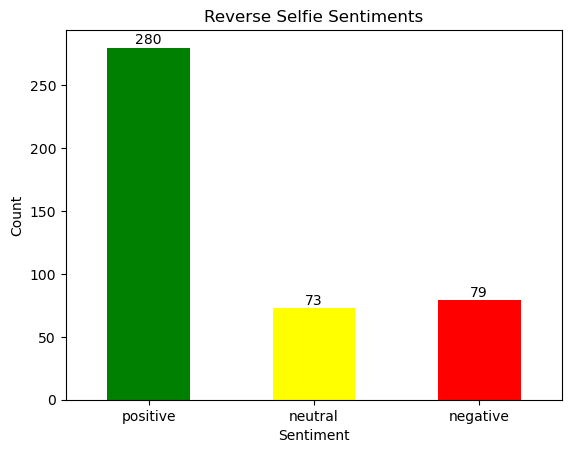

In [6]:
import matplotlib.pyplot as plt

# Select video_id
video_id = 'z2T-Rh838GA'

# Filter by ID
video_df = filtered_df[filtered_df['video_id'] == video_id]

# Count sentiments for that video
sentiment_counts = video_df['sentiment'].value_counts().reindex(['positive', 'neutral', 'negative'])

# Plot
ax = sentiment_counts.plot(kind='bar', color=['green', 'yellow', 'red'])

plt.title(f"Reverse Selfie Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.xticks(rotation=0)


# Add counts above bars
for i, count in enumerate(sentiment_counts):
    ax.text(i, count + 0.5, str(count), ha='center', va='bottom')

plt.show()

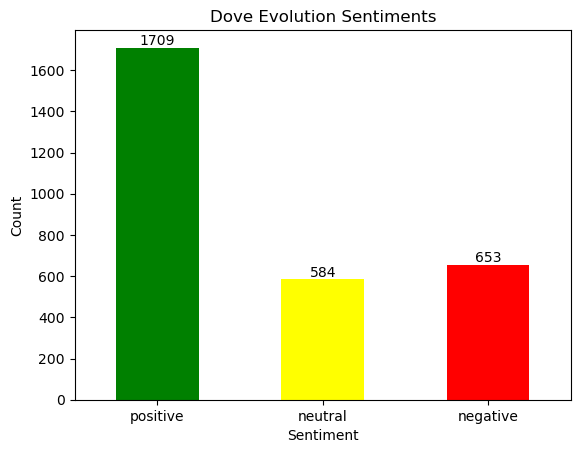

In [7]:
import matplotlib.pyplot as plt

# Select video_id
video_id = 'iYhCn0jf46U'

# Filter by ID
video_df = filtered_df[filtered_df['video_id'] == video_id]

# Count sentiments for video
sentiment_counts = video_df['sentiment'].value_counts().reindex(['positive', 'neutral', 'negative'])

# Plot
ax = sentiment_counts.plot(kind='bar', color=['green', 'yellow', 'red'])

plt.title(f"Dove Evolution Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.xticks(rotation=0)

# Add counts above bars
for i, count in enumerate(sentiment_counts):
    ax.text(i, count + 0.5, str(count), ha='center', va='bottom')

plt.show()